# Headline-only News Topic Classification
### TF-IDF + Logistic Regression vs. MiniLM Sentence Embeddings + Logistic Regression

**NLP Course Project, Option 3: News Topic Classification** · Section 1 · Group 2

| Role | Name | Student ID |
|---|---|---|
| Team leader | Mohammed Saeed Alamodi | 2240009007 |
| Member 2 | Abdulaziz Mohammed Alkhlawi | 2240006095 |
| Member 3 | Jaber Saleh Alsaikhan | 2240006539 |

**Task.** Input: one English news headline (usually 5 to 12 words). Output: one of four topics, **World, Sports, Business or Sci/Tech**. News aggregators, feed readers and newsroom tools often see only the headline, so the topic has to be predicted from a few words.

**Experimental question.** *If only the headline is available, does a pretrained sentence-embedding classifier separate Business and Sci/Tech headlines more reliably than TF-IDF logistic regression?* Besides accuracy and macro-F1 we report the F1 of these two classes and count the Business ↔ Sci/Tech confusions of each method.

**How to run.** Written for **Google Colab** (*Runtime → Run all*); it also runs in local **Jupyter** after `pip install -r requirements.txt`. A GPU is optional (it only speeds up Method 2). All paths are relative to this notebook's folder. Everything that is computed (cleaned splits, models, metrics, figures) is written to `data/processed/`, `models/` and `results/`.

| Section | Content | Main owner |
|---|---|---|
| 0 Setup | packages, versions, paths, shared text helpers | Team leader |
| 1 Data | download, data-quality checks, cleaning, duplicate-aware split | Team leader |
| 2 Method 1 | TF-IDF + logistic regression, tuned on the dev set | Member 2 |
| 3 Method 2 | MiniLM sentence embeddings + logistic regression, tuned on the dev set | Member 3 |
| 4 Results | test-set comparison, answer to the question, error analysis, extra k-NN check | All members |
| 5 Try it | classify a new headline with the saved models (no retraining) | Team leader |
| 6 Sources | data, models, libraries, AI assistance | All members |

## 0. Setup
Installs anything that is missing (Colab already ships most packages), imports the libraries, fixes the random seed and prints the package versions used for the saved results.

In [1]:
# Install only the packages that are missing (nothing is installed if they are all present).
import importlib.util
import subprocess
import sys

REQUIRED = {  # import name -> pip package name
    "numpy": "numpy", "pandas": "pandas", "sklearn": "scikit-learn", "scipy": "scipy",
    "matplotlib": "matplotlib", "joblib": "joblib", "torch": "torch",
    "sentence_transformers": "sentence-transformers", "kagglehub": "kagglehub",
}
missing = [package for module, package in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required packages are already installed.")

# Optional, for Google Colab: work inside a copy of our GitHub repository so that "Try it" can use the saved
# models in models/ without retraining. With REPO_URL empty, everything simply runs in the current folder.
REPO_URL = ""  # e.g. "https://github.com/<user>/<repository>.git"
if "google.colab" in sys.modules and REPO_URL:
    import os
    from pathlib import Path
    repo_folder = Path("/content") / Path(REPO_URL).stem
    if not repo_folder.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(repo_folder)], check=True)
    os.chdir(repo_folder)
    print("Working inside the cloned repository:", repo_folder.name)

All required packages are already installed.


In [2]:
import os

os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")  # harmless cache warning on Windows
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")     # keep the saved outputs readable
os.environ.setdefault("HF_HUB_VERBOSITY", "error")

import warnings

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm notice when ipywidgets is missing

import hashlib
import html
import json
import platform
import random
import re
import time
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sentence_transformers
import sklearn
import torch
from IPython.display import display
from scipy.stats import binomtest
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

# Cap the CPU threads of the numerical libraries. On some multi-core laptops the default (one thread per
# logical core in both OpenBLAS and OpenMP) makes the logistic regressions dozens of times slower.
CPU_THREADS = max(1, min(4, os.cpu_count() or 1))
threadpool_limits(limits=CPU_THREADS)
torch.set_num_threads(max(1, min(8, os.cpu_count() or 1)))   # PyTorch (MiniLM encoding on CPU)

try:  # hide the "Loading weights" progress bar of the transformers library
    from transformers.utils import logging as hf_logging
    hf_logging.set_verbosity_error()
    hf_logging.disable_progress_bar()
except Exception:
    pass

NOTEBOOK_START = time.time()
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

IN_COLAB = "google.colab" in sys.modules
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# All paths are relative to the folder that contains this notebook.
DATA_DIR = Path("data")
RAW_DIR, PROCESSED_DIR = DATA_DIR / "raw", DATA_DIR / "processed"
MODEL_DIR, RESULTS_DIR, CACHE_DIR = Path("models"), Path("results"), Path("cache")
FIG_DIR = RESULTS_DIR / "figures"
for folder in (RAW_DIR, PROCESSED_DIR, MODEL_DIR, FIG_DIR, CACHE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

LABELS = ["World", "Sports", "Business", "Sci/Tech"]        # AG News "Class Index" 1, 2, 3, 4
LABEL_OF_INDEX = {i + 1: name for i, name in enumerate(LABELS)}
BUS, SCI = LABELS.index("Business"), LABELS.index("Sci/Tech")  # row/column positions in confusion matrices
METHODS = ["TF-IDF + LR", "MiniLM + LR"]
EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 160)
VERSIONS = {
    "python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__, "scipy": scipy.__version__, "matplotlib": matplotlib.__version__,
    "torch": torch.__version__, "sentence-transformers": sentence_transformers.__version__,
}
print("Runtime:", "Google Colab" if IN_COLAB else "local Jupyter", "| device:", DEVICE)
print(" | ".join(f"{name} {version}" for name, version in VERSIONS.items()))

Runtime: local Jupyter | device: cpu
python 3.13.7 | numpy 2.5.2 | pandas 3.0.5 | scikit-learn 1.9.1 | scipy 1.18.1 | matplotlib 3.11.1 | torch 2.14.0+cpu | sentence-transformers 6.2.0


In [3]:
# Figure style. Each method keeps the same colour in every figure: blue = TF-IDF, orange = MiniLM.
METHOD_COLORS = {"TF-IDF + LR": "#2a78d6", "MiniLM + LR": "#eb6834"}
INK, INK_SOFT, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
# Figures are drawn at their printed size (3.4 in = one report column, 7 in = full width), so 8 pt text
# stays 8 pt in the report; they are shown larger in the notebook (figure.dpi).
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["DejaVu Sans"], "font.size": 8,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.6, "axes.labelcolor": INK_SOFT, "axes.labelsize": 8,
    "axes.titlesize": 8.5, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.frameon": False, "legend.fontsize": 7.5,
    "lines.linewidth": 1.6, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.03, "figure.dpi": 150,
})


def save_figure(fig, name: str) -> None:
    """Save a figure as results/figures/<name>.png (300 dpi) and show it in the notebook."""
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()

In [4]:
# ---- Shared text helpers: used for the training data AND for new headlines in "Try it" ----

# Publisher / agency tags that AG News appends to titles, e.g. "Oil hits record (Reuters)".
# They are not part of the headline and they leak the label (see 1.2), so they are removed.
SOURCE_TAGS = [
    "AP", "Reuters", "AFP", "Canadian Press", "NewsFactor", "washingtonpost.com", "PC World", "SPACE.com",
    "USATODAY.com", "Ziff Davis", "InfoWorld", "MacCentral", "Forbes.com", "SiliconValley.com", "TechWeb",
    "Investor's Business Daily", "TheDeal.com", "FT.com", "The Motley Fool", "Getty Images", "Los Angeles Times",
    "BusinessWeek Online", "Chicago Tribune", "Editor and Publisher", "AdWeek.com", "New York Post", "Variety",
    "The Sporting News", "PRNewswire",
]
SOURCE_TAG_PATTERN = "|".join(re.escape(tag) for tag in SOURCE_TAGS) + (
    r"|U\.S\. News\s*(?:&\s*)?World Report"                    # "(U.S. News & World Report)"
    r"|Update\s*\d+|Udpate\s*\d+"                               # Bloomberg-style "(Update1)" markers
    r"|updated?(?:\s+[AP]M\s+[\d:]+)?|Correct(?:ed|ion)?|page\s+\d+"
)
SOURCE_TAG_RE = re.compile(r"\s*\((?:" + SOURCE_TAG_PATTERN + r")\)", flags=re.IGNORECASE)
BROKEN_ENTITY_RE = re.compile(r"(^|\s)(#\d+|quot|amp|lt|gt|apos|nbsp);")  # "&" was lost: "children #39;s"
TRUNCATION_RE = re.compile(r"<b>\s*\.\.\.\s*</b>", flags=re.IGNORECASE)   # RSS cut-off marker "<b>...</b>"
HTML_TAG_RE = re.compile(r"<[^>]+>")
TYPOGRAPHY = str.maketrans({"‘": "'", "’": "'", "“": '"', "”": '"',
                            "–": "-", "—": "-", "…": "...", "\xa0": " "})


def repair_encoding(text: str) -> str:
    """Undo the HTML and escape leftovers found in AG News titles."""
    text = text.replace("\\$", "$")                                   # "\$5bn" -> "$5bn"
    text = BROKEN_ENTITY_RE.sub(lambda m: html.unescape("&" + m.group(2) + ";"), text)
    text = html.unescape(html.unescape(text))                         # "&lt;b&gt;" -> "<b>" (twice: double escapes)
    text = TRUNCATION_RE.sub(" ", text)                               # drop "<b>...</b>"
    text = HTML_TAG_RE.sub(" ", text)                                 # "<em>El Reg</em>" -> "El Reg"
    return text.translate(TYPOGRAPHY)


def clean_title(text) -> str:
    """Cleaning applied to every headline: repair the encoding, remove source tags, tidy the spaces."""
    if not isinstance(text, str):
        return ""
    text = SOURCE_TAG_RE.sub(" ", repair_encoding(text))
    return re.sub(r"\s+", " ", text).strip()


def normalize_key(text: str) -> str:
    """Key for duplicate detection: lower-case letters and digits only (case and punctuation ignored)."""
    return re.sub(r"[^a-z0-9]+", " ", text.lower()).strip()


demo_titles = [
    "Google #39;s IPO price range cut (Reuters)",
    "AT amp;T Wins \\$1B Treasury Contract",
    "Junk faxes to be legalized as  quot;opt-out? quot;",
    "Scientists Say Fossil Fuel Emissions Warming Arctic Faster Than &lt;b&gt;...&lt;/b&gt;",
    "Stocks Up; Oil Falls (Update2)",
]
pd.DataFrame({"raw title": demo_titles, "after clean_title()": [clean_title(t) for t in demo_titles]})

,raw title,after clean_title()
0,Google #39;s IPO price range cut (Reuters),Google's IPO price range cut
1,AT amp;T Wins \$1B Treasury Contract,AT&T Wins $1B Treasury Contract
2,Junk faxes to be legalized as quot;opt-out? quot;,"Junk faxes to be legalized as ""opt-out?"""
3,Scientists Say Fossil Fuel Emissions Warming Arctic Faster Than &lt;b&gt;...&lt;/b&gt;,Scientists Say Fossil Fuel Emissions Warming Arctic Faster Than
4,Stocks Up; Oil Falls (Update2),Stocks Up; Oil Falls


## 1. Data  *(Team leader)*

### 1.1 Source and labels
We use the CSV version of **AG News** with separate *Title* and *Description* columns ([Kaggle: amananandrai/ag-news-classification-dataset](https://www.kaggle.com/datasets/amananandrai/ag-news-classification-dataset)). AG News was built by Zhang et al. [1] from A. Gulli's AG corpus of web news articles. We use **only the Title column and the class label**; the description is never shown to either model.

`get_ag_news()` looks for `data/raw/train.csv` and `data/raw/test.csv`. If they are missing it downloads them from Kaggle with `kagglehub` (no Kaggle account is needed for this public dataset). If Kaggle cannot be reached it falls back to a GitHub mirror of the original AG News CSV files, which contain the same rows.

In [5]:
KAGGLE_DATASET = "amananandrai/ag-news-classification-dataset"
MIRROR_URL = "https://raw.githubusercontent.com/mhjabreel/CharCnn_Keras/master/data/ag_news_csv/{}.csv"


def get_ag_news() -> str:
    """Make sure data/raw/train.csv and data/raw/test.csv exist; return where they came from."""
    targets = {split: RAW_DIR / f"{split}.csv" for split in ("train", "test")}
    if all(path.exists() for path in targets.values()):
        return "existing files in data/raw/"
    try:
        import kagglehub
        folder = Path(kagglehub.dataset_download(KAGGLE_DATASET))
        for split, path in targets.items():
            path.write_bytes((folder / f"{split}.csv").read_bytes())
        return f"Kaggle dataset {KAGGLE_DATASET} (via kagglehub)"
    except Exception as error:  # e.g. Kaggle is blocked on this network
        print(f"Kaggle download failed ({error!r}); using the GitHub mirror of the original CSV files.")
        for split, path in targets.items():
            frame = pd.read_csv(MIRROR_URL.format(split), header=None, keep_default_na=False,
                                names=["Class Index", "Title", "Description"])
            frame.to_csv(path, index=False)
        return "GitHub mirror of the original AG News CSV files"


data_source = get_ag_news()
# keep_default_na=False keeps titles such as "NA" as text instead of turning them into missing values
raw = {split: pd.read_csv(RAW_DIR / f"{split}.csv", keep_default_na=False) for split in ("train", "test")}
for frame in raw.values():
    frame["label"] = frame["Class Index"].map(LABEL_OF_INDEX)

print("Data source:", data_source)
class_table = pd.DataFrame({"Official training set": raw["train"]["label"].value_counts(),
                            "Official test set": raw["test"]["label"].value_counts()}).loc[LABELS].T
class_table["Total"] = class_table.sum(axis=1)
class_table

Data source: existing files in data/raw/


label,World,Sports,Business,Sci/Tech,Total
Official training set,30000,30000,30000,30000,120000
Official test set,1900,1900,1900,1900,7600


In [6]:
words = raw["train"]["Title"].str.split().str.len()
print(f"Title length in words: mean {words.mean():.1f}, median {words.median():.0f}, "
      f"5th-95th percentile {words.quantile(0.05):.0f}-{words.quantile(0.95):.0f}, longest {words.max()}")
pd.concat([raw["train"][raw["train"]["label"] == label].head(2) for label in LABELS])[["label", "Title"]]

Title length in words: mean 6.8, median 7, 5th-95th percentile 4-10, longest 19


,label,Title
492,World,Venezuelans Vote Early in Referendum on Chavez Rule (Reuters)
493,World,S.Koreans Clash with Police on Iraq Troop Dispatch (Reuters)
448,Sports,"Phelps, Thorpe Advance in 200 Freestyle (AP)"
449,Sports,Reds Knock Padres Out of Wild-Card Lead (AP)
0,Business,Wall St. Bears Claw Back Into the Black (Reuters)
1,Business,Carlyle Looks Toward Commercial Aerospace (Reuters)
78,Sci/Tech,"'Madden,' 'ESPN' Football Score in Different Ways (Reuters)"
79,Sci/Tech,Group to Propose New High-Speed Wireless Format (Reuters)


### 1.2 Data-quality checks
The proposal listed four problems found in the downloaded files. The cells below measure each one again, plus one problem we only noticed while building the notebook (the `#NAME?` rows).

**(a) Spreadsheet errors.** In the Kaggle copy, 17 titles (15 train, 2 test) read `#NAME?`. The original titles started with "-" (for example `-Posted by dan.farber 5:25 am (PDT)`), and a spreadsheet program treated them as formulas. They are not headlines, so we drop these rows. The row numbers are fixed, so the GitHub-mirror fallback drops exactly the same rows.

In [7]:
SPREADSHEET_ERROR_ROWS = {
    "train": [21463, 23121, 23320, 23782, 30997, 37060, 42727, 43162, 48235, 49737, 65123, 66015, 83969, 93286, 112256],
    "test": [1899, 3869],
}
for split, frame in raw.items():
    rows = frame.loc[SPREADSHEET_ERROR_ROWS[split]]
    print(f"{split}: {len(rows)} rows dropped ({(rows['Title'] == '#NAME?').sum()} read '#NAME?' in this copy); "
          f"labels: {rows['label'].value_counts().to_dict()}")

train: 15 rows dropped (15 read '#NAME?' in this copy); labels: {'Sci/Tech': 12, 'Sports': 2, 'World': 1}
test: 2 rows dropped (2 read '#NAME?' in this copy); labels: {'Sci/Tech': 2}


**(b) Encoding leftovers.** Many titles contain HTML entities whose `&` was lost (`Google #39;s` for *Google's*, `AT amp;T` for *AT&T*, ` quot;` for a quotation mark), escaped tags such as the RSS cut-off marker `&lt;b&gt;...&lt;/b&gt;`, and escaped dollar signs (`\$1bn`). `repair_encoding()` turns them back into normal text.

In [8]:
titles = raw["train"]["Title"]
needs_repair = titles.map(repair_encoding) != titles
encoding_counts = pd.Series({
    "HTML entity remnants (#39; quot; amp; &lt; ...)": titles.str.contains(r"#\d+;|&[a-zA-Z]+;|(?:^|\s)(?:quot|amp|lt|gt);").sum(),
    "  of which end with the cut-off marker <b>...</b>": titles.str.contains("&lt;b&gt;...&lt;/b&gt;", regex=False).sum(),
    "Escaped dollar sign \\$": titles.str.contains(r"\\\$").sum(),
    "Titles changed by repair_encoding()": needs_repair.sum(),
}, name="training titles")
display(encoding_counts.to_frame())
sample = titles[needs_repair].sample(6, random_state=SEED)
pd.DataFrame({"raw title": sample.values, "after repair_encoding()": sample.map(repair_encoding).values})

,training titles
HTML entity remnants (#39; quot; amp; &lt; ...),12967
of which end with the cut-off marker <b>...</b>,2559
Escaped dollar sign \$,2646
Titles changed by repair_encoding(),15318


,raw title,after repair_encoding()
0,"Icahn Offers \$5.4 Billion for Mylan, Drug Maker","Icahn Offers $5.4 Billion for Mylan, Drug Maker"
1,"Tennis: Roddick, Hewitt, Moya and Federer to be missing from &lt;b&gt;...&lt;/b&gt;","Tennis: Roddick, Hewitt, Moya and Federer to be missing from"
2,Unemployment rate dropped slightly last month to 7.1 per cent &lt;b&gt;...&lt;/b&gt;,Unemployment rate dropped slightly last month to 7.1 per cent
3,New breed of portable media players means squinting at palm-sized &lt;b&gt;...&lt;/b&gt;,New breed of portable media players means squinting at palm-sized
4,He Won #39;t Coach Mississippi; Saban Talks to Dolphins,He Won't Coach Mississippi; Saban Talks to Dolphins
5,UPDATE 4-Viacom posts profit; sets \$8 billion buyback,UPDATE 4-Viacom posts profit; sets $8 billion buyback


**(c) Source tags.** Titles often end with the agency or publisher in brackets. The proposal named `(Reuters)`, `(AP)` and `(AFP)`. Checking all tags showed many more, and some are almost pure label signals: `(PC World)`, `(Ziff Davis)` and `(SPACE.com)` are always Sci/Tech, `(Canadian Press)` is always World and `(Update1)` is usually Business. A model would learn the publisher instead of the headline, which would also make the Business/Sci-Tech question look easier than it is. We therefore remove all the publisher tags listed in `SOURCE_TAGS`; bracketed text that belongs to the headline, such as a score, is kept.

In [9]:
def find_source_tag(title: str):
    """Return the publisher tag of a raw title, e.g. 'Reuters' for '... (Reuters)', else None."""
    match = SOURCE_TAG_RE.search(repair_encoding(title))
    if not match:
        return None
    tag = match.group(0).strip()[1:-1]
    return "Update<n>" if re.match(r"(?i)u(?:pd|dp)ate\s*\d+$", tag) else tag


tags = raw["train"]["Title"].map(find_source_tag)
test_tags = raw["test"]["Title"].map(find_source_tag)
print(f"Training titles with a source tag: {tags.notna().sum():,} "
      f"(of which (Reuters)/(AP)/(AFP): {tags.isin(['Reuters', 'AP', 'AFP']).sum():,}); "
      f"test titles with a source tag: {test_tags.notna().sum():,}")

tag_purity = (raw["train"].assign(tag=tags).dropna(subset=["tag"]).groupby("tag")["label"]
              .agg(titles="size", most_common_label=lambda s: s.value_counts().index[0],
                   share_of_that_label=lambda s: s.value_counts(normalize=True).iloc[0])
              .sort_values("titles", ascending=False))
tag_purity["share_of_that_label"] = (100 * tag_purity["share_of_that_label"]).round().astype(int).astype(str) + "%"
tag_purity.head(16)

Training titles with a source tag: 16,849 (of which (Reuters)/(AP)/(AFP): 13,878); test titles with a source tag: 1,074


,titles,most_common_label,share_of_that_label
tag,,,
AP,7692,Sports,40%
Reuters,4231,World,34%
AFP,1955,World,77%
Update<n>,740,Business,78%
Canadian Press,451,World,100%
NewsFactor,253,Sci/Tech,98%
washingtonpost.com,206,Sci/Tech,92%
PC World,190,Sci/Tech,100%
SPACE.com,148,Sci/Tech,100%


**(d) Duplicates, train/test overlap and conflicting labels.** We count these twice: first on the raw lower-cased titles (the method used in the proposal, which reproduces its numbers exactly), then after cleaning, on a normalised key with lower-case letters and digits only. The second count is the one that matters, because it is the text the models actually see. Removing tags merges copies such as `X (Reuters)` and `X (AP)`, so the cleaned counts are higher.

In [10]:
def prepare(frame: pd.DataFrame, split: str) -> pd.DataFrame:
    """Drop spreadsheet-error rows, clean every title and add its duplicate-detection key."""
    out = frame.drop(index=SPREADSHEET_ERROR_ROWS[split]).copy()
    assert not out["Title"].eq("#NAME?").any()
    out["text"] = out["Title"].map(clean_title)
    out["key"] = out["text"].map(normalize_key)
    out = out[out["key"] != ""]                     # nothing left after cleaning (none in practice)
    return out.rename_axis("row_id").reset_index()[["row_id", "label", "Title", "text", "key"]]


def duplicate_stats(train_keys: pd.Series, train_labels: pd.Series, test_keys: pd.Series) -> dict:
    """Repeats, label conflicts and train/test overlap for one way of comparing titles."""
    train_keys, train_labels = train_keys.reset_index(drop=True), train_labels.reset_index(drop=True)
    counts = train_keys.value_counts()
    labels_per_key = train_labels.groupby(train_keys).nunique()
    conflicting = labels_per_key[labels_per_key > 1].index
    return {
        "training rows that repeat an earlier title": len(train_keys) - train_keys.nunique(),
        "distinct training titles that occur more than once": int((counts > 1).sum()),
        "titles with more than one label (conflicts)": len(conflicting),
        "training rows carrying a conflicting title": int(train_keys.isin(conflicting).sum()),
        "test titles that also appear in training": int(test_keys.isin(set(train_keys)).sum()),
    }


clean = {split: prepare(frame, split) for split, frame in raw.items()}
lower = lambda s: s.str.lower().str.strip()
duplicate_table = pd.DataFrame({
    "raw lower-cased titles (proposal)": duplicate_stats(lower(raw["train"]["Title"]), raw["train"]["label"],
                                                          lower(raw["test"]["Title"])),
    "cleaned titles (used here)": duplicate_stats(clean["train"]["key"], clean["train"]["label"], clean["test"]["key"]),
})
duplicate_table

,raw lower-cased titles (proposal),cleaned titles (used here)
training rows that repeat an earlier title,6361,10827
distinct training titles that occur more than once,5207,8666
titles with more than one label (conflicts),652,1149
training rows carrying a conflicting title,1523,2724
test titles that also appear in training,764,1235


### 1.3 Cleaning and the duplicate-aware train/dev/test split
* Training titles with **conflicting labels** are label noise and are removed from training.
* Test titles that also occur in the **training file** (any label) are removed, so no test headline was seen during training. Test titles that carry two different labels inside the test set are removed as well.
* Repeats with the same label stay, and all copies of a headline go to the **same split**. We make the 90/10 train/dev split over *unique headlines*, stratified by label, and then map the rows back.
* The development set is used to choose settings. The cleaned test set is used **once**, for the final comparison.

In [11]:
train_all, test_all = clean["train"], clean["test"]

labels_per_key = train_all.groupby("key")["label"].nunique()
conflict_keys = set(labels_per_key[labels_per_key > 1].index)
train_final = train_all[~train_all["key"].isin(conflict_keys)]

seen_in_training = set(train_all["key"])               # every cleaned training title, conflicts included
test_unseen = test_all[~test_all["key"].isin(seen_in_training)]
test_labels_per_key = test_unseen.groupby("key")["label"].nunique()
test_final = test_unseen[~test_unseen["key"].isin(set(test_labels_per_key[test_labels_per_key > 1].index))]

cleaning_log = pd.DataFrame([
    ("Official CSV files", len(raw["train"]), len(raw["test"])),
    ("Drop '#NAME?' spreadsheet-error rows", len(train_all), len(test_all)),
    ("Drop training titles with conflicting labels", len(train_final), len(test_all)),
    ("Drop test titles that also occur in training", len(train_final), len(test_unseen)),
    ("Drop test titles with conflicting labels", len(train_final), len(test_final)),
], columns=["step", "training rows", "test rows"]).set_index("step")
cleaning_log

,training rows,test rows
step,,
Official CSV files,120000,7600
Drop '#NAME?' spreadsheet-error rows,119985,7598
Drop training titles with conflicting labels,117261,7598
Drop test titles that also occur in training,117261,6363
Drop test titles with conflicting labels,117261,6357


In [12]:
# 90/10 split over unique headlines (each key has exactly one label after the conflict removal),
# stratified by label, so every copy of a repeated headline lands in the same split.
unique_titles = train_final.drop_duplicates("key")[["key", "label"]]
_, dev_keys = train_test_split(unique_titles["key"], test_size=0.10, stratify=unique_titles["label"],
                               random_state=SEED)
is_dev = train_final["key"].isin(set(dev_keys))
splits = {
    "train": train_final[~is_dev].reset_index(drop=True),
    "dev": train_final[is_dev].reset_index(drop=True),
    "test": test_final.reset_index(drop=True),
}

# Fairness check: no headline may be shared between two splits.
for first, second in [("train", "dev"), ("train", "test"), ("dev", "test")]:
    shared = set(splits[first]["key"]) & set(splits[second]["key"])
    assert not shared, f"{len(shared)} headlines are shared between {first} and {second}"
print("Check passed: no headline is shared between train, dev and test.")

for name, frame in splits.items():
    frame.to_csv(PROCESSED_DIR / f"{name}.csv", index=False)

X = {name: frame["text"].tolist() for name, frame in splits.items()}                # cleaned headlines
y = {name: frame["label"].map(LABELS.index).to_numpy() for name, frame in splits.items()}  # 0..3

split_table = pd.DataFrame({name: frame["label"].value_counts() for name, frame in splits.items()}).loc[LABELS].T
split_table["Total"] = split_table.sum(axis=1)
split_table["Share of rows"] = (split_table["Total"] / split_table.loc[["train", "dev"], "Total"].sum()).map("{:.1%}".format)
split_table.loc["test", "Share of rows"] = "-"
split_table

Check passed: no headline is shared between train, dev and test.


label,World,Sports,Business,Sci/Tech,Total,Share of rows
train,26565,26855,26072,26077,105569,90.0%
dev,2927,2965,2907,2893,11692,10.0%
test,1639,1735,1537,1446,6357,-


## 2. Method 1: TF-IDF + logistic regression  *(Member 2)*

**Idea.** Each headline becomes a sparse vector of word *n*-gram weights. TF-IDF gives a high weight to words that are frequent in the headline but rare in the corpus. A multinomial logistic regression then learns one weight per *n*-gram and class. This is the classic strong baseline for AG News [1]. It only knows words it has seen in training.

**Settings.** Lower-casing, accent stripping, the default scikit-learn tokeniser, sublinear term frequency, and `min_df = 2` (an *n*-gram must occur in at least two training headlines). Following the proposal, we tune the **n-gram range** (unigrams vs. unigrams + bigrams) and the **regularisation strength C** on the development set, and keep the combination with the best **dev macro-F1**. The logistic regression uses the `saga` solver, which gives the same scores as the default `lbfgs` on these sparse features but is several times faster.

In [13]:
NGRAM_OPTIONS = {(1, 1): "unigrams", (1, 2): "unigrams + bigrams"}
C_OPTIONS_TFIDF = [0.25, 0.5, 1, 2, 4, 8, 16]


def make_vectorizer(ngram_range) -> TfidfVectorizer:
    return TfidfVectorizer(ngram_range=ngram_range, min_df=2, sublinear_tf=True, lowercase=True,
                           strip_accents="unicode")


def make_logreg(C: float, solver: str = "lbfgs") -> LogisticRegression:
    return LogisticRegression(C=C, solver=solver, max_iter=5000, random_state=SEED)


start = time.time()
rows = []
for ngram_range, ngram_name in NGRAM_OPTIONS.items():
    vectorizer = make_vectorizer(ngram_range)
    X_train_tfidf = vectorizer.fit_transform(X["train"])      # vocabulary learned from training data only
    X_dev_tfidf = vectorizer.transform(X["dev"])
    for C in C_OPTIONS_TFIDF:
        dev_pred = make_logreg(C, "saga").fit(X_train_tfidf, y["train"]).predict(X_dev_tfidf)
        rows.append({"ngrams": ngram_name, "ngram_range": ngram_range, "C": C, "features": X_train_tfidf.shape[1],
                     "dev_accuracy": accuracy_score(y["dev"], dev_pred),
                     "dev_macro_f1": f1_score(y["dev"], dev_pred, average="macro")})
tfidf_dev = pd.DataFrame(rows)
best_tfidf = tfidf_dev.loc[tfidf_dev["dev_macro_f1"].idxmax()]
BEST_NGRAM, BEST_C_TFIDF = tuple(best_tfidf["ngram_range"]), float(best_tfidf["C"])
print(f"Tuning took {time.time() - start:.0f}s. Selected on dev: {best_tfidf['ngrams']} {BEST_NGRAM}, "
      f"C={BEST_C_TFIDF:g} (dev macro-F1 {best_tfidf['dev_macro_f1']:.4f}, accuracy {best_tfidf['dev_accuracy']:.4f})")
print("Vocabulary size:", tfidf_dev.groupby("ngrams")["features"].first().to_dict())
tfidf_dev.pivot(index="C", columns="ngrams", values="dev_macro_f1").round(4)

Tuning took 26s. Selected on dev: unigrams + bigrams (1, 2), C=8 (dev macro-F1 0.8715, accuracy 0.8719)
Vocabulary size: {'unigrams': 20478, 'unigrams + bigrams': 100466}


ngrams,unigrams,unigrams + bigrams
C,,
0.25,0.8490,0.8469
0.50,0.8597,0.8573
1.00,0.8671,0.8654
2.00,0.8698,0.8705
4.00,0.8689,0.8714
8.00,0.8662,0.8715
16.00,0.8605,0.8679


In [14]:
# Final Method 1 model: the selected settings, trained on the training split only.
tfidf_model = Pipeline([("tfidf", make_vectorizer(BEST_NGRAM)), ("logreg", make_logreg(BEST_C_TFIDF, "saga"))])
tfidf_model.fit(X["train"], y["train"])
joblib.dump(tfidf_model, MODEL_DIR / "tfidf_logreg.joblib", compress=3)
print(f"Saved models/tfidf_logreg.joblib ({(MODEL_DIR / 'tfidf_logreg.joblib').stat().st_size / 1e6:.1f} MB), "
      f"{len(tfidf_model.named_steps['tfidf'].vocabulary_):,} features")

# The n-grams with the largest weight for each class show what the model relies on.
feature_names = tfidf_model.named_steps["tfidf"].get_feature_names_out()
weights = tfidf_model.named_steps["logreg"].coef_
pd.DataFrame({LABELS[k]: feature_names[np.argsort(weights[k])[::-1][:12]] for k in range(len(LABELS))})

Saved models/tfidf_logreg.joblib (4.1 MB), 100,466 features


,World,Sports,Business,Sci/Tech
0,arafat,nhl,oil,nasa
1,iraq,bryant,dollar,microsoft
2,iran,cup,enron,space
3,iraqi,nba,yukos,internet
4,darfur,sox,economy,spam
5,sudan,coach,profit,ibm
6,afghan,nascar,stocks,linux
7,hostage,expos,delta,apple
8,sharon,nfl,martha,firefox
9,israel,wenger,treasuries,ipod


## 3. Method 2: MiniLM sentence embeddings + logistic regression  *(Member 3)*

**Idea.** `all-MiniLM-L6-v2` [2, 3] is a small pretrained transformer (6 layers, 22M parameters) from the sentence-transformers library. It was distilled from a larger model and then trained on more than one billion sentence pairs so that sentences with similar meaning get similar vectors. Each headline becomes one **384-dimensional embedding** (mean of the token vectors, L2-normalised). The encoder stays **frozen**: we never update its weights. Only a logistic regression is trained on top of the embeddings. Because the model has seen a very large amount of text, it may handle company and product names, and paraphrases, that never occur in our training data.

**Settings.** Embeddings are computed once and **cached** in `cache/` (keyed by a hash of the model name and the headlines), so re-running the notebook does not re-encode. Encoding takes about 1 minute on a Colab GPU and roughly 7 to 15 minutes on a CPU. Before the logistic regression, each of the 384 dimensions is **standardised** (zero mean and unit variance, fitted on the training split only). This puts all dimensions on the same scale, so C regularises them equally, and the optimiser then converges in seconds instead of minutes. The regularisation strength **C** is chosen on the development set by macro-F1.

In [15]:
encoder = SentenceTransformer(EMBEDDING_MODEL, device=DEVICE)   # downloads ~90 MB the first time
print(encoder)


def embed(texts: list, name: str) -> np.ndarray:
    """MiniLM embeddings for a list of headlines, cached as cache/<name>_<hash>.npy."""
    digest = hashlib.sha256((EMBEDDING_MODEL + "\n" + "\n".join(texts)).encode("utf-8")).hexdigest()[:12]
    path = CACHE_DIR / f"minilm_{name}_{digest}.npy"
    if path.exists():
        print(f"{name}: loaded cached embeddings {path}")
        return np.load(path)
    start = time.time()
    vectors = encoder.encode(texts, batch_size=256, normalize_embeddings=True, convert_to_numpy=True,
                             show_progress_bar=False).astype(np.float32)
    np.save(path, vectors)
    print(f"{name}: encoded {len(texts):,} headlines in {time.time() - start:.0f}s on {DEVICE}")
    return vectors


emb = {name: embed(X[name], name) for name in ("train", "dev", "test")}
print("Embedding matrix shapes:", {name: matrix.shape for name, matrix in emb.items()})

SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'BertModel'})
  (1): Pooling({'embedding_dimension': 384, 'pooling_mode': 'mean', 'include_prompt': True})
  (2): Normalize({'module_input_name': 'sentence_embedding', 'module_output_name': 'sentence_embedding'})
)
train: loaded cached embeddings cache\minilm_train_71dbb9f83c9f.npy
dev: loaded cached embeddings cache\minilm_dev_c512bdb106f7.npy
test: loaded cached embeddings cache\minilm_test_940ee866a667.npy
Embedding matrix shapes: {'train': (105569, 384), 'dev': (11692, 384), 'test': (6357, 384)}


In [16]:
C_OPTIONS_MINILM = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1]


def make_embedding_classifier(C: float) -> Pipeline:
    """Standardise the 384 embedding dimensions (fitted on training data), then logistic regression."""
    return Pipeline([("scale", StandardScaler()), ("logreg", make_logreg(C))])


start = time.time()
rows = []
for C in C_OPTIONS_MINILM:
    dev_pred = make_embedding_classifier(C).fit(emb["train"], y["train"]).predict(emb["dev"])
    rows.append({"C": C, "dev_accuracy": accuracy_score(y["dev"], dev_pred),
                 "dev_macro_f1": f1_score(y["dev"], dev_pred, average="macro")})
minilm_dev = pd.DataFrame(rows)
best_minilm = minilm_dev.loc[minilm_dev["dev_macro_f1"].idxmax()]
BEST_C_MINILM = float(best_minilm["C"])
print(f"Tuning took {time.time() - start:.0f}s. Selected on dev: C={BEST_C_MINILM:g} "
      f"(dev macro-F1 {best_minilm['dev_macro_f1']:.4f}, accuracy {best_minilm['dev_accuracy']:.4f})")

# Final Method 2 model: the selected C, trained on the training split only.
minilm_clf = make_embedding_classifier(BEST_C_MINILM).fit(emb["train"], y["train"])
joblib.dump({"classifier": minilm_clf, "encoder_name": EMBEDDING_MODEL, "normalize_embeddings": True,
             "labels": LABELS}, MODEL_DIR / "minilm_logreg.joblib", compress=3)
print("Saved models/minilm_logreg.joblib")
minilm_dev.round(4)

Tuning took 13s. Selected on dev: C=0.003 (dev macro-F1 0.8335, accuracy 0.8339)


Saved models/minilm_logreg.joblib


,C,dev_accuracy,dev_macro_f1
0,0.001,0.8332,0.8328
1,0.003,0.8339,0.8335
2,0.010,0.8336,0.8332
3,0.030,0.8337,0.8333
4,0.100,0.8333,0.8328
5,0.300,0.8335,0.8330
6,1.000,0.8335,0.8330


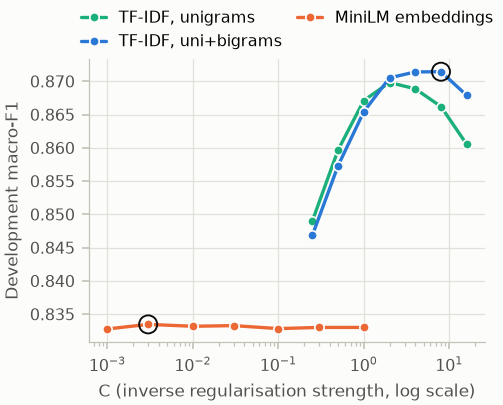

In [17]:
# Development-set tuning curves for both methods; the selected setting of each method is ringed.
fig, ax = plt.subplots(figsize=(3.4, 2.45))
curves = [(tfidf_dev[tfidf_dev["ngrams"] == "unigrams"], "#1baf7a", "TF-IDF, unigrams"),
          (tfidf_dev[tfidf_dev["ngrams"] == "unigrams + bigrams"], METHOD_COLORS["TF-IDF + LR"], "TF-IDF, uni+bigrams"),
          (minilm_dev, METHOD_COLORS["MiniLM + LR"], "MiniLM embeddings")]
for part, color, name in curves:
    ax.plot(part["C"], part["dev_macro_f1"], color=color, marker="o", markersize=4.5,
            markeredgecolor=SURFACE, markeredgewidth=0.8, label=name)
for C, score in [(BEST_C_TFIDF, best_tfidf["dev_macro_f1"]), (BEST_C_MINILM, best_minilm["dev_macro_f1"])]:
    ax.scatter([C], [score], s=75, facecolor="none", edgecolor=INK, linewidth=0.9, zorder=4)
ax.set_xscale("log")
ax.set_xlabel("C (inverse regularisation strength, log scale)")
ax.set_ylabel("Development macro-F1")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.22), ncol=2, columnspacing=1.0, handlelength=1.6)
save_figure(fig, "dev_tuning")

## 4. Results  *(all members)*

### 4.1 Test-set comparison
Both final models were trained on the same training split, with settings chosen on the development set. They are now evaluated **once**, on the same cleaned test headlines. None of these headlines occurs in the training or development data.

In [18]:
proba = {"TF-IDF + LR": tfidf_model.predict_proba(X["test"]), "MiniLM + LR": minilm_clf.predict_proba(emb["test"])}
pred = {method: p.argmax(axis=1) for method, p in proba.items()}


def evaluate(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    """Accuracy, macro-F1, per-class F1 and the Business <-> Sci/Tech confusion counts."""
    cm = confusion_matrix(y_true, y_pred, labels=range(len(LABELS)))
    per_class = f1_score(y_true, y_pred, average=None, labels=range(len(LABELS)))
    return {"accuracy": accuracy_score(y_true, y_pred), "macro_f1": f1_score(y_true, y_pred, average="macro"),
            **{f"F1 {label}": per_class[k] for k, label in enumerate(LABELS)},
            "Business -> Sci/Tech": int(cm[BUS, SCI]), "Sci/Tech -> Business": int(cm[SCI, BUS]),
            "Business <-> Sci/Tech total": int(cm[BUS, SCI] + cm[SCI, BUS]), "confusion_matrix": cm}


def scores_only(result: dict) -> dict:
    return {name: value for name, value in result.items() if name != "confusion_matrix"}


test_results = {method: evaluate(y["test"], pred[method]) for method in METHODS}
tfidf_r, minilm_r = test_results["TF-IDF + LR"], test_results["MiniLM + LR"]
table = {}
for name in ["accuracy", "macro_f1"] + [f"F1 {label}" for label in LABELS]:       # scores in %
    table[name] = [f"{100 * tfidf_r[name]:.2f}", f"{100 * minilm_r[name]:.2f}",
                   f"{100 * (minilm_r[name] - tfidf_r[name]):+.2f} pts"]
for name in ["Business -> Sci/Tech", "Sci/Tech -> Business", "Business <-> Sci/Tech total"]:  # counts
    table[name] = [f"{tfidf_r[name]}", f"{minilm_r[name]}", f"{minilm_r[name] - tfidf_r[name]:+d}"]
print(f"Test set: {len(y['test']):,} headlines. Scores in %, confusions are counts of test headlines.")
pd.DataFrame.from_dict(table, orient="index", columns=["TF-IDF + LR", "MiniLM + LR", "MiniLM - TF-IDF"])

Test set: 6,357 headlines. Scores in %, confusions are counts of test headlines.


,TF-IDF + LR,MiniLM + LR,MiniLM - TF-IDF
accuracy,86.49,82.95,-3.54 pts
macro_f1,86.25,82.69,-3.56 pts
F1 World,87.33,84.49,-2.85 pts
F1 Sports,91.20,88.63,-2.57 pts
F1 Business,82.58,77.36,-5.21 pts
F1 Sci/Tech,83.89,80.28,-3.62 pts
Business -> Sci/Tech,139,191,+52
Sci/Tech -> Business,125,155,+30
Business <-> Sci/Tech total,264,346,+82


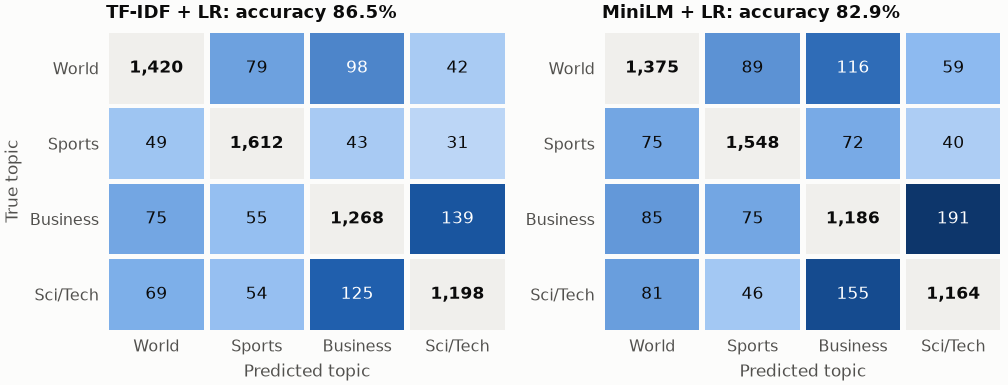

In [19]:
# Confusion matrices. Correct predictions (diagonal) are grey; errors are shaded by count on one shared scale.
error_cmap = matplotlib.colors.LinearSegmentedColormap.from_list("errors", ["#eef4fc", "#86b6ef", "#1c5cab", "#0d366b"])
off_diagonal = ~np.eye(len(LABELS), dtype=bool)
max_error = max(r["confusion_matrix"][off_diagonal].max() for r in test_results.values())
fig, axes = plt.subplots(1, 2, figsize=(6.9, 2.75))
for ax, method in zip(axes, METHODS):
    cm = test_results[method]["confusion_matrix"]
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            share = cm[i, j] / max_error
            face = "#f0efec" if i == j else error_cmap(share)
            ax.add_patch(plt.Rectangle((j - 0.47, i - 0.47), 0.94, 0.94, facecolor=face, edgecolor="none"))
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=8,
                    color="#ffffff" if (i != j and share > 0.5) else INK, fontweight="bold" if i == j else "normal")
    ax.set_xlim(-0.5, len(LABELS) - 0.5)
    ax.set_ylim(len(LABELS) - 0.5, -0.5)
    ax.set_xticks(range(len(LABELS)), LABELS)
    ax.set_yticks(range(len(LABELS)), LABELS)
    ax.tick_params(length=0)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_xlabel("Predicted topic")
    ax.set_title(f"{method}: accuracy {test_results[method]['accuracy']:.1%}")
axes[0].set_ylabel("True topic")
fig.tight_layout()
save_figure(fig, "confusion_matrices")

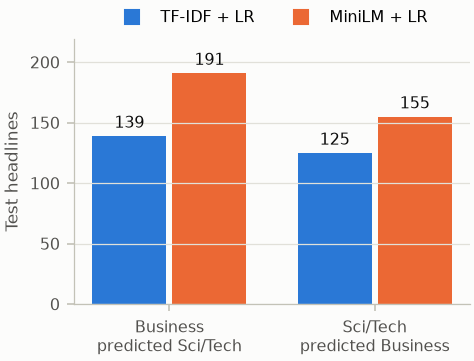

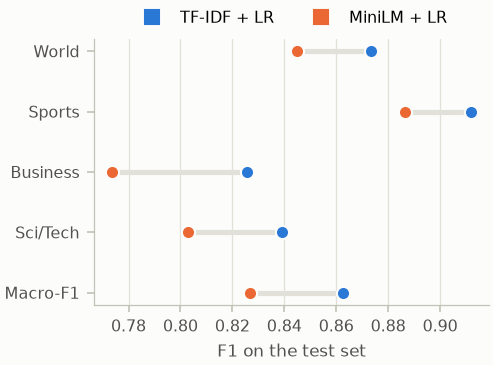

In [20]:
# The numbers the question is about: Business <-> Sci/Tech confusions (left) and per-class F1 (right).
method_handles = [plt.Line2D([], [], marker="s", linestyle="", markersize=7, color=METHOD_COLORS[m]) for m in METHODS]
directions = [("Business\npredicted Sci/Tech", "Business -> Sci/Tech"),
              ("Sci/Tech\npredicted Business", "Sci/Tech -> Business")]
fig, ax = plt.subplots(figsize=(3.4, 2.3))
width = 0.36
top = max(test_results[m][key] for m in METHODS for _, key in directions)
for k, method in enumerate(METHODS):
    values = [test_results[method][key] for _, key in directions]
    positions = np.arange(len(directions)) + (k - 0.5) * (width + 0.03)
    ax.bar(positions, values, width, color=METHOD_COLORS[method])
    for x_pos, value in zip(positions, values):
        ax.text(x_pos, value + top * 0.02, f"{value}", ha="center", va="bottom", fontsize=7.5, color=INK)
ax.set_xticks(range(len(directions)), [name for name, _ in directions])
ax.set_ylim(0, top * 1.15)
ax.set_ylabel("Test headlines")
ax.grid(axis="x", visible=False)
ax.legend(method_handles, METHODS, loc="upper center", bbox_to_anchor=(0.5, 1.16), ncol=2)
save_figure(fig, "bst_confusions")

fig, ax = plt.subplots(figsize=(3.4, 2.3))
rows = [f"F1 {label}" for label in LABELS] + ["macro_f1"]
for i, row in enumerate(rows):
    values = [test_results[m][row] for m in METHODS]
    ax.plot(values, [i, i], color=GRID, linewidth=2.5, zorder=1)
    for method, value in zip(METHODS, values):
        ax.scatter(value, i, s=40, color=METHOD_COLORS[method], edgecolor=SURFACE, linewidth=1, zorder=3)
ax.set_yticks(range(len(rows)), LABELS + ["Macro-F1"])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("F1 on the test set")
ax.legend(method_handles, METHODS, loc="upper center", bbox_to_anchor=(0.5, 1.16), ncol=2)
save_figure(fig, "per_class_f1")

### 4.2 Answering the question: is the difference real?
Both methods are scored on the same headlines, so we use paired tests:
* **McNemar's exact test** looks only at headlines where exactly one method is right. If the two methods were equally good, each would win about half of these.
* A **paired bootstrap** (2,000 resamples of the test set) gives a 95% confidence interval for each difference (MiniLM minus TF-IDF), including the difference in Business ↔ Sci/Tech confusions.

In [21]:
def mcnemar_exact(right_a: np.ndarray, right_b: np.ndarray):
    """Exact McNemar test: two-sided binomial test on the headlines where only one method is right."""
    only_a, only_b = int(np.sum(right_a & ~right_b)), int(np.sum(~right_a & right_b))
    p_value = binomtest(only_a, only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0
    return only_a, only_b, p_value


def scores_from_matrix(cm: np.ndarray) -> np.ndarray:
    """[macro-F1, F1 Business, F1 Sci/Tech, B<->S confusions, accuracy] from a confusion matrix."""
    tp = np.diag(cm).astype(float)
    denominator = 2 * tp + (cm.sum(axis=0) - tp) + (cm.sum(axis=1) - tp)
    f1 = np.divide(2 * tp, denominator, out=np.zeros_like(tp), where=denominator > 0)
    return np.array([f1.mean(), f1[BUS], f1[SCI], cm[BUS, SCI] + cm[SCI, BUS], tp.sum() / cm.sum()])


def paired_bootstrap(y_true, pred_a, pred_b, n_boot=2000, seed=SEED) -> np.ndarray:
    """Differences (b - a) of the scores above on n_boot bootstrap resamples of the test set."""
    rng, n, k = np.random.default_rng(seed), len(y_true), len(LABELS)
    diffs = np.empty((n_boot, 5))
    for i in range(n_boot):
        idx = rng.integers(0, n, n)
        cm_a = np.bincount(y_true[idx] * k + pred_a[idx], minlength=k * k).reshape(k, k)
        cm_b = np.bincount(y_true[idx] * k + pred_b[idx], minlength=k * k).reshape(k, k)
        diffs[i] = scores_from_matrix(cm_b) - scores_from_matrix(cm_a)
    return diffs


right = {method: pred[method] == y["test"] for method in METHODS}
is_bus_sci = np.isin(y["test"], [BUS, SCI])
tests = {}
for name, mask in [("all test headlines", np.ones_like(is_bus_sci)), ("Business + Sci/Tech headlines", is_bus_sci)]:
    only_tfidf, only_minilm, p_value = mcnemar_exact(right["TF-IDF + LR"][mask], right["MiniLM + LR"][mask])
    tests[name] = {"headlines": int(mask.sum()), "only TF-IDF right": only_tfidf, "only MiniLM right": only_minilm,
                   "McNemar p-value": p_value}
mcnemar_table = pd.DataFrame(tests).T
mcnemar_table["McNemar p-value"] = mcnemar_table["McNemar p-value"].map(lambda p: f"{p:.2g}")
display(mcnemar_table)

diffs = paired_bootstrap(y["test"], pred["TF-IDF + LR"], pred["MiniLM + LR"])
observed = scores_from_matrix(test_results["MiniLM + LR"]["confusion_matrix"]) - \
           scores_from_matrix(test_results["TF-IDF + LR"]["confusion_matrix"])
low, high = np.percentile(diffs, [2.5, 97.5], axis=0)
names = ["macro-F1", "F1 Business", "F1 Sci/Tech", "Business <-> Sci/Tech confusions", "accuracy"]
bootstrap_table = pd.DataFrame({"MiniLM - TF-IDF": observed, "95% CI low": low, "95% CI high": high}, index=names)
bootstrap_table.loc[names[:3] + names[4:]] *= 100          # scores in percentage points
bootstrap_table["CI excludes 0?"] = (bootstrap_table["95% CI low"] > 0) | (bootstrap_table["95% CI high"] < 0)
bootstrap_table.round(2)

,headlines,only TF-IDF right,only MiniLM right,McNemar p-value
all test headlines,6357.0,531.0,306.0,6.7e-15
Business + Sci/Tech headlines,2983.0,301.0,185.0,1.6e-07


,MiniLM - TF-IDF,95% CI low,95% CI high,CI excludes 0?
macro-F1,-3.56,-4.45,-2.66,True
F1 Business,-5.21,-6.75,-3.69,True
F1 Sci/Tech,-3.62,-5.16,-2.09,True
Business <-> Sci/Tech confusions,82.00,50.00,116.00,True
accuracy,-3.54,-4.39,-2.66,True


**Answer.** No. With headline-only input, the approved pretrained method (frozen MiniLM embeddings + logistic regression) separates Business and Sci/Tech **less** reliably than TF-IDF + logistic regression:
* It makes **346** Business ↔ Sci/Tech confusions against **264** for TF-IDF, 82 more (+31%; 95% bootstrap interval of the difference: 50 to 116).
* Its F1 is **5.2 points lower for Business** (77.4 vs 82.6) and **3.6 points lower for Sci/Tech** (80.3 vs 83.9). Both intervals exclude zero.
* On the 2,983 Business and Sci/Tech test headlines, TF-IDF alone is right 301 times and MiniLM alone 185 times (McNemar p = 1.6 × 10⁻⁷).

The gap is not limited to these two classes. MiniLM is lower on every class and 3.5 points lower in accuracy overall (p = 6.7 × 10⁻¹⁵). Business ↔ Sci/Tech is still the largest confusion for both methods: 264 of TF-IDF's 859 errors and 346 of MiniLM's 1,084.

**Why?** TF-IDF learns sharp, dataset-specific word cues (see the feature table in Section 2). In this 2004 news corpus many company and product names belong almost entirely to one class (*yukos, enron, treasuries* → Business; *nasa, linux, firefox* → Sci/Tech). The frozen embedding compresses the overall meaning of a headline into 384 numbers. "A technology company did something involving money" lands between the two classes, and a linear classifier on top cannot recover the single word that decides the label. Section 4.5 tests whether that information is still in the embedding.

### 4.3 The challenge factors: unfamiliar words and very short headlines
The proposal expected the embeddings to help most on **names and words not seen in training**. We split the test headlines by whether they contain a word outside the TF-IDF vocabulary (a word that appeared in fewer than two training headlines, so TF-IDF has no weight for it) and by headline length. Then we compare accuracy within each group.

,factor,group,headlines,Business/Sci-Tech headlines,TF-IDF + LR accuracy,TF-IDF + LR acc. on Business/Sci-Tech,MiniLM + LR accuracy,MiniLM + LR acc. on Business/Sci-Tech
0,Unfamiliar words,no unseen word,5173,2397,0.8790,0.8465,0.8405,0.7989
1,Unfamiliar words,1+ unseen word,1184,586,0.8032,0.7457,0.7812,0.7423
2,Headline length,1-4 words,922,387,0.8113,0.7416,0.7831,0.7106
3,Headline length,5-6 words,2458,1190,0.8596,0.8277,0.8157,0.7815
4,Headline length,7-8 words,1974,958,0.8870,0.8580,0.8480,0.8121
5,Headline length,9+ words,1003,448,0.8833,0.8304,0.8694,0.8192


,group,headlines,n,only TF-IDF right,only MiniLM right,McNemar p-value
0,no unseen word,all topics,5173,409,210,9.9e-16
1,no unseen word,Business + Sci/Tech,2397,237,123,1.9e-09
2,1+ unseen word,all topics,1184,122,96,0.09
3,1+ unseen word,Business + Sci/Tech,586,64,62,0.93


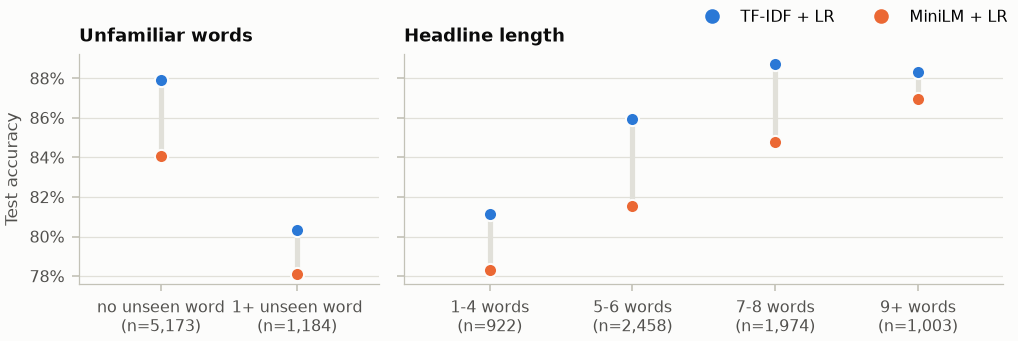

In [22]:
analyzer = tfidf_model.named_steps["tfidf"].build_analyzer()
known_words = {feature for feature in tfidf_model.named_steps["tfidf"].vocabulary_ if " " not in feature}
unigram_analyzer = make_vectorizer((1, 1)).build_analyzer()
unknown_words = [[w for w in unigram_analyzer(text) if w not in known_words] for text in X["test"]]
n_words = np.array([len(text.split()) for text in X["test"]])

groups = {
    "Unfamiliar words": {"no unseen word": np.array([len(u) == 0 for u in unknown_words]),
                         "1+ unseen word": np.array([len(u) > 0 for u in unknown_words])},
    "Headline length": {"1-4 words": n_words <= 4, "5-6 words": (n_words >= 5) & (n_words <= 6),
                        "7-8 words": (n_words >= 7) & (n_words <= 8), "9+ words": n_words >= 9},
}
rows = []
for factor, buckets in groups.items():
    for bucket, mask in buckets.items():
        row = {"factor": factor, "group": bucket, "headlines": int(mask.sum()),
               "Business/Sci-Tech headlines": int((mask & is_bus_sci).sum())}
        for method in METHODS:
            row[f"{method} accuracy"] = right[method][mask].mean()
            row[f"{method} acc. on Business/Sci-Tech"] = right[method][mask & is_bus_sci].mean()
        rows.append(row)
factor_table = pd.DataFrame(rows)
display(factor_table.round(4))

# Paired McNemar test inside each unfamiliar-word group: is the difference still real there?
factor_tests = []
for bucket, mask in groups["Unfamiliar words"].items():
    for subset, sub_mask in [("all topics", mask), ("Business + Sci/Tech", mask & is_bus_sci)]:
        only_tfidf, only_minilm, p_value = mcnemar_exact(right["TF-IDF + LR"][sub_mask], right["MiniLM + LR"][sub_mask])
        factor_tests.append({"group": bucket, "headlines": subset, "n": int(sub_mask.sum()),
                             "only TF-IDF right": only_tfidf, "only MiniLM right": only_minilm,
                             "McNemar p-value": f"{p_value:.2g}"})
factor_tests = pd.DataFrame(factor_tests)
display(factor_tests)

fig, axes = plt.subplots(1, 2, figsize=(6.9, 2.3), sharey=True, gridspec_kw={"width_ratios": [2, 4]})
for ax, (factor, buckets) in zip(axes, groups.items()):
    part = factor_table[factor_table["factor"] == factor].reset_index(drop=True)
    for i, row in part.iterrows():
        values = [row[f"{m} accuracy"] for m in METHODS]
        ax.plot([i, i], values, color=GRID, linewidth=2.5, zorder=1)
        for method, value in zip(METHODS, values):
            ax.scatter(i, value, s=40, color=METHOD_COLORS[method], edgecolor=SURFACE, linewidth=1, zorder=3)
    ax.set_xticks(range(len(part)), [f"{g}\n(n={n:,})" for g, n in zip(part["group"], part["headlines"])])
    ax.set_xlim(-0.6, len(part) - 0.4)
    ax.grid(axis="x", visible=False)
    ax.set_title(factor)
    ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0))
axes[0].set_ylabel("Test accuracy")
handles = [plt.Line2D([], [], marker="o", linestyle="", markersize=6, color=METHOD_COLORS[m]) for m in METHODS]
fig.legend(handles, METHODS, loc="upper right", ncol=2, bbox_to_anchor=(1.0, 1.04))
fig.tight_layout()
save_figure(fig, "challenge_factors")

**What the challenge factors show.**
* **Unfamiliar words.** 1,184 test headlines (19%) contain a word outside the TF-IDF vocabulary. Both methods are worse on them, but TF-IDF loses more (87.9% → 80.3%) than MiniLM (84.1% → 78.1%). On these headlines the difference is **no longer significant** (p = 0.09 over all topics; on Business/Sci-Tech headlines 64 vs 62 wins, p = 0.93). This partly supports the proposal's expectation that pretrained knowledge helps with unseen names: MiniLM catches up there, but it does not overtake TF-IDF.
* **Very short headlines.** Headlines of 1 to 4 words are the hardest for both methods (81.1% and 78.3%), and accuracy rises with length. The gap between the methods is largest for 5 to 6 words (4.4 points) and smallest for 9 or more words (1.4 points), so the embedding benefits more from extra context.

### 4.4 Error analysis
First, where the two methods agree and disagree. Then the most confident Business ↔ Sci/Tech mistakes of each method, and five errors we explain one by one. For each explained headline we show the evidence each model used: for TF-IDF, the n-grams that pushed it most towards its answer (feature value × class weight); for MiniLM, the training headlines closest to it in embedding space (cosine similarity).

In [23]:
test_view = splits["test"][["row_id", "label", "text"]].copy()
for method in METHODS:
    test_view[method] = [LABELS[k] for k in pred[method]]
    test_view[f"{method} conf."] = proba[method].max(axis=1).round(3)

agreement = pd.crosstab(pd.Series(np.where(right["TF-IDF + LR"], "TF-IDF right", "TF-IDF wrong"), name=""),
                        pd.Series(np.where(right["MiniLM + LR"], "MiniLM right", "MiniLM wrong"), name=""))
display(agreement)

for method in METHODS:
    wrong_bs = test_view[is_bus_sci & ~right[method] & np.isin(pred[method], [BUS, SCI])]
    print(f"\n{method}: {len(wrong_bs)} Business <-> Sci/Tech errors. The 8 most confident:")
    display(wrong_bs.sort_values(f"{method} conf.", ascending=False).head(8)
            [["row_id", "label", "text", "TF-IDF + LR", "MiniLM + LR", f"{method} conf."]])

,MiniLM right,MiniLM wrong
,,
TF-IDF right,4967,531
TF-IDF wrong,306,553



TF-IDF + LR: 264 Business <-> Sci/Tech errors. The 8 most confident:


,row_id,label,text,TF-IDF + LR,MiniLM + LR,TF-IDF + LR conf.
3403,4097,Sci/Tech,"Greenspan: Debt, home prices not dangerous",Business,Business,0.999
2769,3334,Business,34 tech firms sued for alleged LCD patent theft,Sci/Tech,Sci/Tech,0.999
1810,2169,Business,"Ask Jeeves retools search engine in bid to catch Google, Yahoo",Sci/Tech,Sci/Tech,0.999
895,1051,Business,Software Service Aims to Outfox Caller ID,Sci/Tech,Sci/Tech,0.999
3789,4571,Business,Microsoft Readies Next Business IM Server,Sci/Tech,Sci/Tech,0.998
3886,4689,Business,Yahoo Debuts Mobile Search,Sci/Tech,Sci/Tech,0.997
2710,3264,Business,CA aquires computer security firm,Sci/Tech,Sci/Tech,0.997
5199,6247,Sci/Tech,Before-the-Bell: GenCorp Falls 5.6 Pct.,Business,Business,0.995



MiniLM + LR: 346 Business <-> Sci/Tech errors. The 8 most confident:


,row_id,label,text,TF-IDF + LR,MiniLM + LR,MiniLM + LR conf.
3403,4097,Sci/Tech,"Greenspan: Debt, home prices not dangerous",Business,Business,0.996
3293,3970,Business,Wi-Fi successor is called high-speed hype -- for now,Sci/Tech,Sci/Tech,0.992
5074,6100,Business,Lazarus-like virus hits computers,Sci/Tech,Sci/Tech,0.991
2644,3183,Business,webcrawler: A9.com is cool,Sci/Tech,Sci/Tech,0.989
2361,2828,Business,IBM Claims Its BlueGene Supercomputer Is the Fastest,Sci/Tech,Sci/Tech,0.987
3042,3672,Business,Rumors Suggest Photo Ability To Be Added to iPod,Sci/Tech,Sci/Tech,0.983
2991,3617,Business,Linux: Paris weighs a shift to open-source camp,Sci/Tech,Sci/Tech,0.981
895,1051,Business,Software Service Aims to Outfox Caller ID,Sci/Tech,Sci/Tech,0.981


In [24]:
# Five errors explained below (row_id = row number in the official Kaggle test.csv).
EXPLAINED_ERRORS = [4097, 3334, 7559, 2590, 4689]
tfidf_vectorizer, tfidf_logreg = tfidf_model.named_steps["tfidf"], tfidf_model.named_steps["logreg"]
tfidf_feature_names = tfidf_vectorizer.get_feature_names_out()


def tfidf_evidence(text: str, k: int, top: int = 3) -> str:
    """The n-grams that pushed TF-IDF most towards class k (TF-IDF value x class weight)."""
    row = tfidf_vectorizer.transform([text]).tocoo()
    contribution = row.data * tfidf_logreg.coef_[k, row.col]
    best = np.argsort(-contribution)[:top]
    return ", ".join(f"'{tfidf_feature_names[row.col[i]]}' {contribution[i]:+.2f}" for i in best)


def nearest_training_headlines(vector: np.ndarray, top: int = 4) -> list:
    """The training headlines most similar to one embedding (cosine similarity; vectors are L2-normalised)."""
    similarity = emb["train"] @ vector
    return [(similarity[j], splits["train"].loc[j, "label"], splits["train"].loc[j, "text"])
            for j in np.argsort(-similarity)[:top]]


row_of = {row_id: i for i, row_id in enumerate(splits["test"]["row_id"])}
for number, row_id in enumerate(EXPLAINED_ERRORS, start=1):
    i = row_of[row_id]
    k_tfidf, k_minilm = pred["TF-IDF + LR"][i], pred["MiniLM + LR"][i]
    print(f'({number}) row {row_id}: "{X["test"][i]}"   true topic: {splits["test"].loc[i, "label"]}')
    print(f"    TF-IDF: {LABELS[k_tfidf]} ({proba['TF-IDF + LR'][i].max():.0%}); "
          f"strongest n-grams for {LABELS[k_tfidf]}: {tfidf_evidence(X['test'][i], k_tfidf)}")
    print(f"    MiniLM: {LABELS[k_minilm]} ({proba['MiniLM + LR'][i].max():.0%}); nearest training headlines:")
    for similarity, label, text in nearest_training_headlines(emb["test"][i]):
        print(f"        {similarity:.2f}  {label:<9} {text}")
    print()

(1) row 4097: "Greenspan: Debt, home prices not dangerous"   true topic: Sci/Tech
    TF-IDF: Business (100%); strongest n-grams for Business: 'debt' +1.98, 'greenspan' +1.93, 'prices' +1.39
    MiniLM: Business (100%); nearest training headlines:
        0.90  Business  Greenspan: Don't Fear US Household Debt, Home Prices
        0.80  Business  Greenspan unperturbed by record US household debt, surging home
        0.79  Business  Greenspan downplays worries over high US household debts
        0.70  Business  Greenspan Not Too Worried by the Rise in Energy Prices

(2) row 3334: "34 tech firms sued for alleged LCD patent theft"   true topic: Business
    TF-IDF: Sci/Tech (100%); strongest n-grams for Sci/Tech: 'lcd' +1.30, 'patent' +1.18, 'tech' +1.17
    MiniLM: Sci/Tech (76%); nearest training headlines:
        0.76  Sci/Tech  Honeywell Sues 34 Companies Over LCD Patent
        0.70  Sci/Tech  Court case looms over LCD patent
        0.69  Sci/Tech  Honeywell sues Apple, 33 others

**The five errors explained**
1. *"Greenspan: Debt, home prices not dangerous"* is labelled **Sci/Tech**; both models answer **Business** with at least 99% confidence. The words (*debt*, *greenspan*, *prices*) and all nearest training headlines (e.g. *"Greenspan: Don't Fear US Household Debt, Home Prices"*, labelled Business) point to Business. A Federal Reserve chairman talking about household debt is economics news, so the Sci/Tech label is almost certainly a labelling error in AG News. Some "errors" are not model failures, which means our test scores slightly understate both models.
2. *"34 tech firms sued for alleged LCD patent theft"* is labelled **Business**; both answer **Sci/Tech**. The event is a lawsuit (business and legal news), but *lcd*, *patent* and *tech* are strong Sci/Tech words. MiniLM's neighbours expose the deeper problem: the same Honeywell LCD-patent story appears in the training data **under both labels** (*"Honeywell Sues 34 Companies Over LCD Patent"* is Sci/Tech, *"Honeywell Sues Apple, Others Over LCD Patent"* is Business). When the gold labels of one story disagree, no headline-only model can always be right. This is exactly the Business/Sci-Tech overlap the proposal anticipated.
3. *"Exploring Andromeda"* is labelled **Sci/Tech**; TF-IDF answers **Business** (46%) and MiniLM **Sci/Tech** (99%). *Andromeda* is outside the TF-IDF vocabulary, so the only feature left is *exploring*, and TF-IDF is effectively guessing. MiniLM knows from pre-training that Andromeda is a galaxy, and its nearest training headlines are about space (*"Hubble Approaches the Final Frontier: The Dawn of Galaxies"*). This is the case the pretrained model was chosen for: a short headline whose key word never occurs in training.
4. *"Before the Bell - ESS Technology drops 4.4 pct"* is labelled **Business**; TF-IDF answers **Business** (99%) and MiniLM **Sci/Tech** (96%). TF-IDF relies on *bell*, *the bell* and *pct*, because "Before the Bell" is a recurring pre-market stock column in the training data. MiniLM's answer is pulled towards technology by the company name *ESS Technology*, even though all four of its nearest training headlines are Business "Before the Bell" stories. The information is in the embedding, but the linear classifier does not use it (tested in 4.5).
5. *"Yahoo Debuts Mobile Search"* is labelled **Business**; both answer **Sci/Tech** with more than 97% confidence. Four words, a technology company and a product launch: *yahoo*, *mobile* and *search* are all strong Sci/Tech cues. Three of MiniLM's four closest training headlines (e.g. *"Yahoo launches mobile web search"*) are Sci/Tech, while a near-identical one (*"Yahoo follows Google; launches web search service for mobiles"*) is Business. Whether a product launch counts as business or technology news depends on the source's editor, not on the words in the headline.

In [25]:
# Difficult cases that were classified correctly: Business/Sci-Tech headlines where both methods are right
# but at least one was unsure (top probability below 0.6).
unsure = is_bus_sci & right["TF-IDF + LR"] & right["MiniLM + LR"] & \
         ((proba["TF-IDF + LR"].max(axis=1) < 0.6) | (proba["MiniLM + LR"].max(axis=1) < 0.6))
print(f"{unsure.sum()} difficult-but-correct Business/Sci-Tech headlines; a sample of 6:")
test_view[unsure].sample(6, random_state=SEED)[["row_id", "label", "text", "TF-IDF + LR conf.", "MiniLM + LR conf."]]

332 difficult-but-correct Business/Sci-Tech headlines; a sample of 6:


,row_id,label,text,TF-IDF + LR conf.,MiniLM + LR conf.
409,473,Business,New Overtime Rules Take Effect,0.906,0.536
5941,7112,Sci/Tech,Ericsson Selected by MTN South Africa to Supply 3G/WCDMA Network,0.580,0.632
1302,1548,Business,"Post-Olympic Greece tightens purse, sells family silver to fill budget holes",0.461,0.485
3393,4086,Sci/Tech,Flat-screen TV emits international distress signal,0.834,0.423
1049,1234,Sci/Tech,French Internet provider Wanadoo will build Dutch broadband network,0.950,0.581
2878,3472,Sci/Tech,Cracks in Martian rock point to watery past,0.475,0.737


### 4.5 Extra experiment: is the linear classifier the bottleneck?
In example (4) above, all of MiniLM's nearest training headlines carry the right topic, yet the logistic regression on the same embedding answers wrongly with 96% confidence. The embedding space may group similar stories well while the four topics are not separable by straight lines (a linear classifier). To test this, we keep the frozen embeddings and replace the logistic regression with a **cosine-weighted k-nearest-neighbour vote**: each of the k most similar training headlines votes for its topic, weighted by its similarity. *This was not part of the proposal.* As with the main methods, **k is chosen on the development set** and the model is scored **once** on the test set. Because AG News often covers the same story in several headlines, we also split the test set by how close its nearest training headline is.

In [26]:
K_OPTIONS = [1, 5, 10, 20, 50]


def nearest_neighbours(queries: np.ndarray, n: int = max(K_OPTIONS), batch: int = 500):
    """Indices and cosine similarities of the n most similar training headlines, most similar first."""
    index_parts, similarity_parts = [], []
    for start in range(0, len(queries), batch):
        similarity = queries[start:start + batch] @ emb["train"].T
        top = np.argpartition(-similarity, n, axis=1)[:, :n]
        top_similarity = np.take_along_axis(similarity, top, axis=1)
        order = np.argsort(-top_similarity, axis=1)
        index_parts.append(np.take_along_axis(top, order, axis=1))
        similarity_parts.append(np.take_along_axis(top_similarity, order, axis=1))
    return np.vstack(index_parts), np.vstack(similarity_parts)


def knn_proba(neighbour_index: np.ndarray, neighbour_similarity: np.ndarray, k: int) -> np.ndarray:
    """Similarity-weighted votes of the k nearest training headlines, scaled to sum to 1."""
    votes = np.zeros((len(neighbour_index), len(LABELS)))
    for j in range(k):
        np.add.at(votes, (np.arange(len(votes)), y["train"][neighbour_index[:, j]]), neighbour_similarity[:, j])
    return votes / votes.sum(axis=1, keepdims=True)


start = time.time()
dev_index, dev_similarity = nearest_neighbours(emb["dev"])
knn_dev = pd.DataFrame([{"k": k, **{name: value for name, value in scores_only(
    evaluate(y["dev"], knn_proba(dev_index, dev_similarity, k).argmax(axis=1))).items()
    if name in ("accuracy", "macro_f1", "Business <-> Sci/Tech total")}} for k in K_OPTIONS])
BEST_K = int(knn_dev.loc[knn_dev["macro_f1"].idxmax(), "k"])
print(f"Selected on dev: k={BEST_K} (search took {time.time() - start:.0f}s)")
display(knn_dev.round(4))

test_index, test_similarity = nearest_neighbours(emb["test"])
knn_test_proba = knn_proba(test_index, test_similarity, BEST_K)
knn_pred = knn_test_proba.argmax(axis=1)
knn_result = evaluate(y["test"], knn_pred)
three_way = pd.DataFrame({"TF-IDF + LR": scores_only(test_results["TF-IDF + LR"]),
                          "MiniLM + LR": scores_only(test_results["MiniLM + LR"]),
                          f"MiniLM + {BEST_K}-NN (extra)": scores_only(knn_result)})
print(f"Test set ({len(y['test']):,} headlines):")
display(three_way.round(4))

knn_right = knn_pred == y["test"]
knn_tests = {}
for name, mask in [("all test headlines", np.ones_like(is_bus_sci)), ("Business + Sci/Tech headlines", is_bus_sci)]:
    only_tfidf, only_knn, p_value = mcnemar_exact(right["TF-IDF + LR"][mask], knn_right[mask])
    knn_tests[name] = {"only TF-IDF right": only_tfidf, "only kNN right": only_knn, "McNemar p-value": f"{p_value:.2g}"}
display(pd.DataFrame(knn_tests).T)

knn_diffs = paired_bootstrap(y["test"], pred["TF-IDF + LR"], knn_pred)
knn_low, knn_high = np.percentile(knn_diffs, [2.5, 97.5], axis=0)
knn_bootstrap = pd.DataFrame({"kNN - TF-IDF": scores_from_matrix(knn_result["confusion_matrix"])
                              - scores_from_matrix(test_results["TF-IDF + LR"]["confusion_matrix"]),
                              "95% CI low": knn_low, "95% CI high": knn_high}, index=names)
knn_bootstrap.loc[names[:3] + names[4:]] *= 100            # scores in percentage points
display(knn_bootstrap.round(2))

# How close is each test headline to its most similar training headline?
closest = test_similarity[:, 0]
closeness = {"very close (cosine >= 0.8)": closest >= 0.8, "less close (cosine < 0.8)": closest < 0.8}
paraphrase_table = pd.DataFrame({group: {"headlines": int(mask.sum()),
                                         "TF-IDF + LR": right["TF-IDF + LR"][mask].mean(),
                                         "MiniLM + LR": right["MiniLM + LR"][mask].mean(),
                                         f"MiniLM + {BEST_K}-NN": knn_right[mask].mean()}
                                 for group, mask in closeness.items()}).T
paraphrase_table

Selected on dev: k=10 (search took 13s)


,k,accuracy,macro_f1,Business <-> Sci/Tech total
0,1,0.8660,0.8658,534
1,5,0.8829,0.8826,505
2,10,0.8866,0.8862,471
3,20,0.8836,0.8831,465
4,50,0.8765,0.8760,484


Test set (6,357 headlines):


,TF-IDF + LR,MiniLM + LR,MiniLM + 10-NN (extra)
accuracy,0.8649,0.8295,0.8838
macro_f1,0.8625,0.8269,0.8816
F1 World,0.8733,0.8449,0.8970
F1 Sports,0.9120,0.8863,0.9284
F1 Business,0.8258,0.7736,0.8396
F1 Sci/Tech,0.8389,0.8028,0.8614
Business -> Sci/Tech,139.0000,191.0000,126.0000
Sci/Tech -> Business,125.0000,155.0000,130.0000
Business <-> Sci/Tech total,264.0000,346.0000,256.0000


,only TF-IDF right,only kNN right,McNemar p-value
all test headlines,245,365,1.3e-06
Business + Sci/Tech headlines,146,215,0.00033


,kNN - TF-IDF,95% CI low,95% CI high
macro-F1,1.91,1.16,2.70
F1 Business,1.38,0.11,2.66
F1 Sci/Tech,2.25,0.95,3.62
Business <-> Sci/Tech confusions,-8.00,-38.00,21.00
accuracy,1.89,1.15,2.67


,headlines,TF-IDF + LR,MiniLM + LR,MiniLM + 10-NN
very close (cosine >= 0.8),1784.0,0.922085,0.891256,0.932175
less close (cosine < 0.8),4573.0,0.842554,0.805379,0.864859


**Result.** The information *is* in the embeddings. With a 10-nearest-neighbour vote instead of logistic regression, the **same frozen** MiniLM embeddings reach **88.4% accuracy and 88.2 macro-F1** on the test set. That is 1.9 points above TF-IDF and 5.5 above MiniLM + LR, and the difference with TF-IDF is significant (McNemar p = 1.3 × 10⁻⁶). This variant also has the best Business F1 (84.0) and Sci/Tech F1 (86.1) of the three. On the 2,983 Business and Sci/Tech headlines, it is right where TF-IDF is wrong 215 times and the reverse happens 146 times (p = 0.0003). The number of direct Business ↔ Sci/Tech swaps, however, is about the same as TF-IDF's (256 vs 264; the bootstrap interval of the difference includes 0). Its gain on these two classes comes mostly from fewer confusions with World and Sports. The gain is also not just repeated stories: kNN is ahead both on test headlines that have a very similar training headline (93.2% vs 92.2%) and on all the others (86.5% vs 84.3%).

So the negative answer in 4.2 is about the **linear classifier**, not about the pretrained representation. The topics form local groups in the embedding space, but straight lines cannot separate them. Two cautions:
* The k-NN variant was added *after* we saw the error analysis and goes beyond the approved proposal, so we report it as a finding to confirm, not as our main result.
* It has a practical cost: every prediction compares the new headline with all 105,569 stored training embeddings (about 160 MB), so it is not used in *Try it*.

### 4.6 Our own headlines (not part of the test scores)
Each member wrote two new headlines with the label they intended. They are not from AG News and are kept **separate from the test results**. They only show how the saved models behave on unfamiliar text.

In [27]:
ORIGINAL_EXAMPLES = [  # (member, headline written by the member, intended label)
    ("Team leader", "Central bank raises interest rates for the third time this year", "Business"),
    ("Team leader", "Astronomers detect water vapour on a planet orbiting a nearby star", "Sci/Tech"),
    ("Member 2", "Striker scores twice as underdogs reach the cup final", "Sports"),
    ("Member 2", "Chip maker's profit triples on demand for AI servers", "Business"),
    ("Member 3", "New phone app translates sign language into text in real time", "Sci/Tech"),
    ("Member 3", "Ceasefire talks resume as aid convoys cross the border", "World"),
]
own = pd.DataFrame(ORIGINAL_EXAMPLES, columns=["member", "headline", "intended label"])
own_texts = own["headline"].map(clean_title).tolist()
own_proba = {"TF-IDF + LR": tfidf_model.predict_proba(own_texts),
             "MiniLM + LR": minilm_clf.predict_proba(encoder.encode(own_texts, normalize_embeddings=True))}
for method in METHODS:
    own[method] = [f"{LABELS[p.argmax()]} ({p.max():.0%})" for p in own_proba[method]]
own["both correct?"] = [all(LABELS[own_proba[m][i].argmax()] == label for m in METHODS)
                        for i, label in enumerate(own["intended label"])]
for method in METHODS:
    hits = sum(LABELS[p.argmax()] == label for p, label in zip(own_proba[method], own["intended label"]))
    print(f"{method}: {hits} of {len(own)} of our headlines get the intended label")
own

TF-IDF + LR: 5 of 6 of our headlines get the intended label
MiniLM + LR: 5 of 6 of our headlines get the intended label


,member,headline,intended label,TF-IDF + LR,MiniLM + LR,both correct?
0,Team leader,Central bank raises interest rates for the third time this year,Business,Business (81%),Business (97%),True
1,Team leader,Astronomers detect water vapour on a planet orbiting a nearby star,Sci/Tech,Sci/Tech (97%),Sci/Tech (79%),True
2,Member 2,Striker scores twice as underdogs reach the cup final,Sports,Sports (100%),Sports (98%),True
3,Member 2,Chip maker's profit triples on demand for AI servers,Business,Sci/Tech (90%),Sci/Tech (88%),False
4,Member 3,New phone app translates sign language into text in real time,Sci/Tech,Sci/Tech (92%),Sci/Tech (85%),True
5,Member 3,Ceasefire talks resume as aid convoys cross the border,World,World (99%),World (99%),True


### 4.7 Check: what if we had kept the source tags?
To show why the tags were removed, we retrain the selected TF-IDF model on the *same* training rows with the tags left in. We score it on the development set, also with tags. The test set is not used here.

In [28]:
with_tags = lambda frame: [re.sub(r"\s+", " ", repair_encoding(t)).strip() for t in frame["Title"]]
leaky_model = Pipeline([("tfidf", make_vectorizer(BEST_NGRAM)), ("logreg", make_logreg(BEST_C_TFIDF))])
leaky_model.fit(with_tags(splits["train"]), y["train"])
leak_check = pd.DataFrame({
    "tags removed (our model)": scores_only(evaluate(y["dev"], tfidf_model.predict(X["dev"]))),
    "tags kept": scores_only(evaluate(y["dev"], leaky_model.predict(with_tags(splits["dev"])))),
}).loc[["accuracy", "macro_f1", "F1 Business", "F1 Sci/Tech", "Business <-> Sci/Tech total"]]
leak_check["difference"] = leak_check["tags kept"] - leak_check["tags removed (our model)"]
leak_check.round(4)

,tags removed (our model),tags kept,difference
accuracy,0.8719,0.8788,0.0069
macro_f1,0.8715,0.8784,0.0069
F1 Business,0.8434,0.8552,0.0118
F1 Sci/Tech,0.8508,0.8558,0.0051
Business <-> Sci/Tech total,493.0000,465.0000,-28.0000


**Result.** Keeping the tags raises the development accuracy of the same TF-IDF model by about 0.7 points and its Business F1 by about 1.2 points, with 28 fewer Business ↔ Sci/Tech confusions. Those extra points come from the publisher, not from the headline. A feed reader or newsroom tool would not always receive the tag, and its meaning would differ across sources, so removing the tags gives an honest headline-only estimate.

In [29]:
# Save everything the report and slides use, so the numbers can be checked without re-running.
def plain(value):
    """Convert numpy values to plain Python so they can be written as JSON."""
    if isinstance(value, dict):
        return {str(k): plain(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [plain(v) for v in value]
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    return value


SELECTED_MODEL = max(METHODS, key=lambda m: {"TF-IDF + LR": best_tfidf["dev_macro_f1"],
                                             "MiniLM + LR": best_minilm["dev_macro_f1"]}[m])
(MODEL_DIR / "selected_model.json").write_text(json.dumps({
    "selected_model": SELECTED_MODEL, "rule": "higher development macro-F1",
    "dev_macro_f1": {"TF-IDF + LR": best_tfidf["dev_macro_f1"], "MiniLM + LR": best_minilm["dev_macro_f1"]},
}, indent=2))

metrics = {
    "created": datetime.now(timezone.utc).isoformat(timespec="seconds"), "versions": VERSIONS, "device": DEVICE,
    "data_source": data_source,
    "cleaning_log": cleaning_log.reset_index().to_dict("records"),
    "duplicates": duplicate_table.to_dict(),
    "split_sizes": split_table["Total"].to_dict(),
    "split_class_counts": split_table[LABELS].to_dict("index"),
    "method1": {"ngram_range": BEST_NGRAM, "C": BEST_C_TFIDF, "dev_macro_f1": best_tfidf["dev_macro_f1"],
                "dev_accuracy": best_tfidf["dev_accuracy"], "features": len(tfidf_model.named_steps["tfidf"].vocabulary_)},
    "method2": {"encoder": EMBEDDING_MODEL, "C": BEST_C_MINILM, "dev_macro_f1": best_minilm["dev_macro_f1"],
                "dev_accuracy": best_minilm["dev_accuracy"]},
    "selected_model": SELECTED_MODEL,
    "test": test_results,
    "mcnemar": tests,
    "bootstrap": bootstrap_table.drop(columns="CI excludes 0?").to_dict("index"),
    "challenge_factors": factor_table.to_dict("records"),
    "challenge_factor_tests": factor_tests.to_dict("records"),
    "knn_extra": {"k": BEST_K, "dev": knn_dev.to_dict("records"), "test": knn_result, "mcnemar_vs_tfidf": knn_tests,
                  "bootstrap_vs_tfidf": knn_bootstrap.to_dict("index"),
                  "closeness": paraphrase_table.to_dict("index")},
    "agreement": {"both right": int((right["TF-IDF + LR"] & right["MiniLM + LR"]).sum()),
                  "only TF-IDF right": int((right["TF-IDF + LR"] & ~right["MiniLM + LR"]).sum()),
                  "only MiniLM right": int((~right["TF-IDF + LR"] & right["MiniLM + LR"]).sum()),
                  "both wrong": int((~right["TF-IDF + LR"] & ~right["MiniLM + LR"]).sum())},
    "leak_check_dev": leak_check.to_dict(),
}
(RESULTS_DIR / "metrics.json").write_text(json.dumps(plain(metrics), indent=2))
test_view.to_csv(RESULTS_DIR / "test_predictions.csv", index=False)
tfidf_dev.assign(ngram_range=tfidf_dev["ngram_range"].astype(str)).to_csv(RESULTS_DIR / "dev_tuning_tfidf.csv", index=False)
minilm_dev.to_csv(RESULTS_DIR / "dev_tuning_minilm.csv", index=False)
own.to_csv(RESULTS_DIR / "original_examples.csv", index=False)
print("Saved results/metrics.json, test_predictions.csv, dev_tuning_*.csv, original_examples.csv and figures/*.png")
print(f"Selected model for 'Try it' (higher dev macro-F1): {SELECTED_MODEL}")

Saved results/metrics.json, test_predictions.csv, dev_tuning_*.csv, original_examples.csv and figures/*.png
Selected model for 'Try it' (higher dev macro-F1): TF-IDF + LR


## 5. Try it  *(Team leader)*
Type a headline into `headline` and run the cell. In Colab the line with `#@param` turns into a text box. The prediction comes from the **saved** models in `models/`, so nothing is retrained. If the models are already saved, you only need to run **0. Setup** first; sections 1 to 4 can be skipped. The *selected model* is the one with the higher development macro-F1; the other model's answer is shown as a second opinion.

In [30]:
def load_saved_models():
    """Load both trained models and the MiniLM encoder from disk (no training happens here)."""
    tfidf = joblib.load(MODEL_DIR / "tfidf_logreg.joblib")
    minilm = joblib.load(MODEL_DIR / "minilm_logreg.joblib")
    selected = json.loads((MODEL_DIR / "selected_model.json").read_text())["selected_model"]
    return tfidf, minilm, SentenceTransformer(minilm["encoder_name"], device=DEVICE), selected


SAVED_TFIDF, SAVED_MINILM, SAVED_ENCODER, SELECTED = load_saved_models()


def predict_topic(headline: str) -> pd.DataFrame:
    """Probability of each topic for one headline, from both saved models (rows = topics)."""
    text = clean_title(headline)
    vector = SAVED_ENCODER.encode([text], normalize_embeddings=True)
    return pd.DataFrame({"TF-IDF + LR": SAVED_TFIDF.predict_proba([text])[0],
                         "MiniLM + LR": SAVED_MINILM["classifier"].predict_proba(vector)[0]}, index=LABELS)


def show_prediction(headline) -> None:
    """Print a readable prediction for one headline, or a helpful message for empty input."""
    if not isinstance(headline, str) or not headline.strip():
        print("Please type a news headline first, for example: 'Oil prices climb as supply fears grow'.")
        return
    if not clean_title(headline):
        print("Nothing is left after cleaning (only a source tag or markup?). Please type the headline text.")
        return
    probs = predict_topic(headline)
    best = probs[SELECTED]
    other = [m for m in METHODS if m != SELECTED][0]
    print(f'Headline: "{headline.strip()}"')
    print(f"Predicted topic: {best.idxmax()}  ({best.max():.0%} confidence, {SELECTED})")
    for label in LABELS:
        print(f"   {label:<9}{best[label]:>6.1%}  {'█' * round(best[label] * 30)}")
    print(f"Second opinion ({other}): {probs[other].idxmax()} ({probs[other].max():.0%})")
    if len(headline.split()) > 30:
        print("Note: the models were trained on headlines (about 7 words); long texts may be less reliable.")

In [31]:
#@title Try it: type a headline and run this cell
headline = "Electric carmaker's shares slide after battery recall"  #@param {type:"string"}
show_prediction(headline)

Headline: "Electric carmaker's shares slide after battery recall"
Predicted topic: Business  (85% confidence, TF-IDF + LR)
   World      1.6%  
   Sports     1.7%  █
   Business  84.9%  █████████████████████████
   Sci/Tech  11.8%  ████
Second opinion (MiniLM + LR): Business (68%)


In [32]:
# Empty or blank input gives a helpful message instead of an error:
show_prediction("")
show_prediction("    ")
print()
# More unfamiliar headlines (written by us, not from AG News):
for new_headline in ["Streaming giant raises subscription prices in 40 countries",
                     "Quantum computer solves chemistry problem faster than supercomputers",
                     "Rain delays opening day of the cricket test in Brisbane"]:
    show_prediction(new_headline)
    print()
print(f"Total notebook run time: {(time.time() - NOTEBOOK_START) / 60:.1f} minutes")

Please type a news headline first, for example: 'Oil prices climb as supply fears grow'.
Please type a news headline first, for example: 'Oil prices climb as supply fears grow'.

Headline: "Streaming giant raises subscription prices in 40 countries"
Predicted topic: Sci/Tech  (39% confidence, TF-IDF + LR)
   World     22.5%  ███████
   Sports     2.1%  █
   Business  36.1%  ███████████
   Sci/Tech  39.4%  ████████████
Second opinion (MiniLM + LR): Business (84%)

Headline: "Quantum computer solves chemistry problem faster than supercomputers"
Predicted topic: Sci/Tech  (100% confidence, TF-IDF + LR)
   World      0.0%  
   Sports     0.0%  
   Business   0.2%  
   Sci/Tech  99.8%  ██████████████████████████████
Second opinion (MiniLM + LR): Sci/Tech (96%)

Headline: "Rain delays opening day of the cricket test in Brisbane"
Predicted topic: Sports  (98% confidence, TF-IDF + LR)
   World      1.0%  
   Sports    98.1%  █████████████████████████████
   Business   0.3%  
   Sci/Tech   0.7%

## 6. Sources
**Data**
* AG News, CSV with Title/Description columns, uploaded to Kaggle by user *amananandrai*: https://www.kaggle.com/datasets/amananandrai/ag-news-classification-dataset. Built from A. Gulli's AG corpus of news articles by Zhang et al. [1]. Fallback copy: https://github.com/mhjabreel/CharCnn_Keras (original AG News CSV).

**Pretrained model**
* `sentence-transformers/all-MiniLM-L6-v2`, https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2 (Apache-2.0), loaded with the sentence-transformers library [2]. It is based on MiniLM [3]. Its weights are used frozen.

**Libraries**: Python, pandas, NumPy, scikit-learn (TF-IDF, logistic regression, metrics), SciPy (binomial test for McNemar), PyTorch and sentence-transformers (embeddings), kagglehub (download), matplotlib (figures), joblib (saving models).

**References**
1. X. Zhang, J. Zhao, and Y. LeCun, "Character-level convolutional networks for text classification," in *Advances in Neural Information Processing Systems 28*, 2015, pp. 649–657.
2. N. Reimers and I. Gurevych, "Sentence-BERT: Sentence embeddings using Siamese BERT-networks," in *Proc. EMNLP-IJCNLP*, 2019, pp. 3982–3992.
3. W. Wang, F. Wei, L. Dong, H. Bao, N. Yang, and M. Zhou, "MiniLM: Deep self-attention distillation for task-agnostic compression of pre-trained transformers," in *Advances in Neural Information Processing Systems 33*, 2020.

**AI assistance.** Parts of this notebook's code and text were drafted with the help of an AI assistant (Claude, Anthropic). The team reviewed, ran and checked all code and results, and is responsible for the content. No code was copied from other groups.